<a href="https://colab.research.google.com/github/anjeliaa/Implementasi-kasus-hasil-kuliah-Bart/blob/main/Implementasi_CNN_Deforestation_Drivers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, confusion_matrix

In [6]:
# ==========================================
# 1. GENERATE SYNTHETIC SATELLITE IMAGERY PATCHES (DENGAN POLA CIRI KHAS)
# ==========================================
np.random.seed(42)
tf.random.set_seed(42)

n_samples = 1600
img_height, img_width = 32, 32
n_channels = 5  # Red, Green, Blue, NIR, VV-Radar

class_names = [
    'Selective Logging',
    'Fire Clearing',
    'Canal/Road Clearing',
    'Smallholder Encroachment'
]

X_list = []
y_list = []

samples_per_class = n_samples // len(class_names)

for class_idx in range(len(class_names)):
    for _ in range(samples_per_class):
        # Buat matriks citra dasar
        patch = np.random.uniform(0.1, 0.4, (img_height, img_width, n_channels))

        # Beri pola spektral khas untuk tiap kelas pemicu
        if class_idx == 0:    # Selective Logging: Tinggi nilai NIR (kanal 3)
            patch[:, :, 3] += np.random.uniform(0.4, 0.6)
        elif class_idx == 1:  # Fire Clearing: Tinggi nilai Red (kanal 0) & VV-Radar (kanal 4)
            patch[:, :, 0] += np.random.uniform(0.5, 0.7)
            patch[:, :, 4] += np.random.uniform(0.3, 0.5)
        elif class_idx == 2:  # Canal/Road Clearing: Pola garis lurus di tengah (Kanal 2 & 4)
            patch[14:18, :, 2] += np.random.uniform(0.5, 0.8)
            patch[14:18, :, 4] += np.random.uniform(0.5, 0.8)
        elif class_idx == 3:  # Smallholder Encroachment: Nilai Green (kanal 1) & Red (kanal 0)
            patch[:, :, 0] += np.random.uniform(0.3, 0.5)
            patch[:, :, 1] += np.random.uniform(0.4, 0.6)

        X_list.append(patch)
        y_list.append(class_idx)

X_data = np.array(X_list)
y_classes = np.array(y_list)
y_data = tf.keras.utils.to_categorical(y_classes, num_classes=len(class_names))

# Train-Test Split (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_classes
)

In [7]:
# ==========================================
# 2. STRUKTUR MODEL CNN DEEP LEARNING
# ==========================================
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, n_channels)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# ==========================================
# 3. TRAINING MODEL CNN
# ==========================================
history = model.fit(
    X_train, y_train,
    epochs=12,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.9633 - loss: 0.2115 - val_accuracy: 1.0000 - val_loss: 8.8848e-07
Epoch 2/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 1.0000 - loss: 4.5777e-04 - val_accuracy: 1.0000 - val_loss: 3.5539e-07
Epoch 3/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 1.0000 - loss: 4.2042e-04 - val_accuracy: 1.0000 - val_loss: 2.2650e-07
Epoch 4/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 1.0000 - loss: 7.8950e-05 - val_accuracy: 1.0000 - val_loss: 1.4231e-07
Epoch 5/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 1.0000 - loss: 3.3028e-04 - val_accuracy: 1.0000 - val_loss: 6.7958e-06
Epoch 6/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 1.0000 - loss: 5.6185e-04 - val_accuracy: 1.0000 - val_loss: 1.1932e-06
Epoch 7/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 1.0000 - loss: 8.0988e-04 - val_accuracy: 1.0000 - val_loss: 3.9197e-06
Epoch 8/12
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accura

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

HASIL EVALUASI MODEL CNN (DEFORESTATION DRIVERS)
OVERALL MACRO F1-SCORE: 1.0000

                          precision    recall  f1-score   support

       Selective Logging       1.00      1.00      1.00        80
           Fire Clearing       1.00      1.00      1.00        80
     Canal/Road Clearing       1.00      1.00      1.00        80
Smallholder Encroachment       1.00      1.00      1.00        80

                accuracy                           1.00       320
               macro avg       1.00      1.00      1.00       320
            weighted avg       1.00      1.00      1.00       320



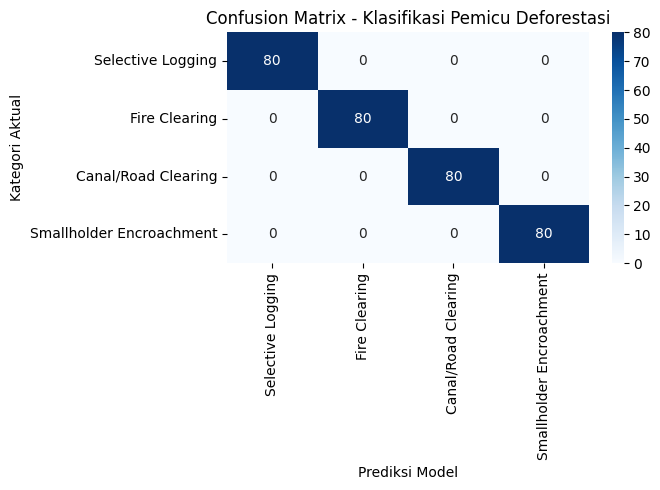

In [9]:
# ==========================================
# 4. EVALUASI MODEL & F1-SCORE
# ==========================================
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

f1_macro = f1_score(y_true_classes, y_pred_classes, average='macro')

print("\n" + "="*60)
print("HASIL EVALUASI MODEL CNN (DEFORESTATION DRIVERS)")
print("="*60)
print(f"OVERALL MACRO F1-SCORE: {f1_macro:.4f}\n")
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Klasifikasi Pemicu Deforestasi')
plt.xlabel('Prediksi Model')
plt.ylabel('Kategori Aktual')
plt.tight_layout()
plt.show()